# PyRainCloud — быстрый старт

Rain cloud plot = облако плотности (half-violin) + box plot + сырые точки («дождь»). Одна функция: `rc.raincloud(data, x, y)`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pyraincloud as rc

rc.__version__

'0.1.0'

## 1. Данные
Длинный формат: одна строка — одно наблюдение, колонка-группа и числовая колонка.

In [2]:
rng = np.random.default_rng(42)
df = pd.DataFrame(
    {
        "group": ["Control"] * 30 + ["Treatment A"] * 30 + ["Treatment B"] * 30,
        "reaction_time": np.concatenate(
            [rng.normal(500, 50, 30), rng.normal(450, 60, 30), rng.normal(480, 55, 30)]
        ),
    }
)
df.head()

,group,reaction_time
0,Control,515.235854
1,Control,448.000795
2,Control,537.522560
3,Control,547.028236
4,Control,402.448241


## 2. Базовый график — одна команда

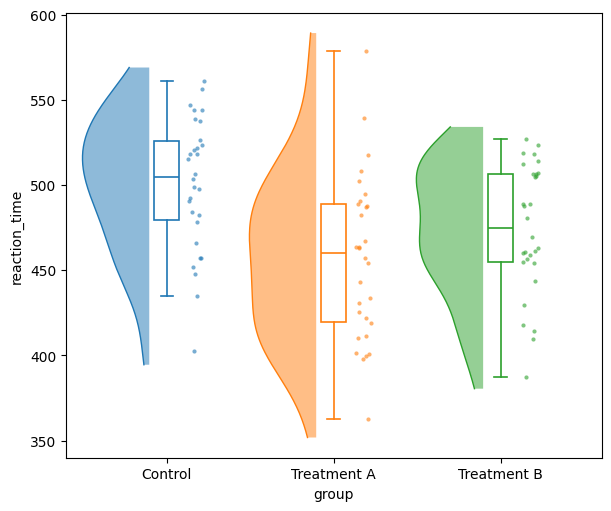

In [3]:
fig, ax = rc.raincloud(data=df, x="group", y="reaction_time")

## 3. Кастомизация слоёв

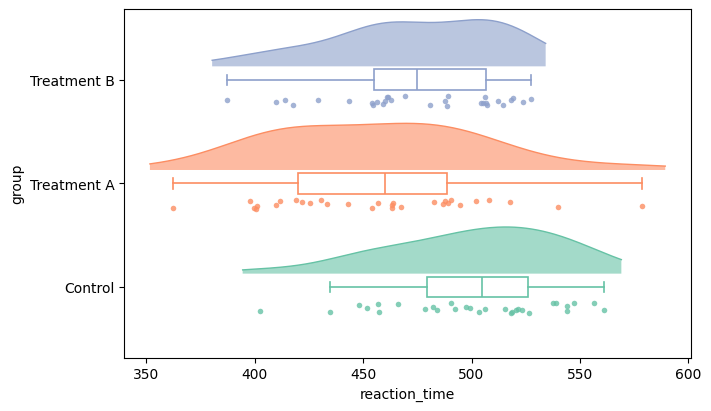

In [4]:
palette = ["#66c2a5", "#fc8d62", "#8da0cb"]
fig, ax = rc.raincloud(
    data=df,
    x="group",
    y="reaction_time",
    orient="h",
    palette=palette,
    cloud_alpha=0.6,
    cloud_width=0.9,
    point_size=4,
    point_alpha=0.8,
    box_width=0.2,
    random_state=0,
)

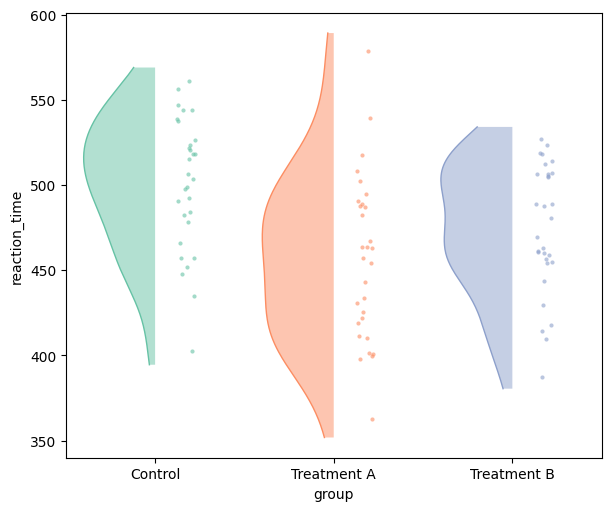

In [5]:
fig, ax = rc.raincloud(
    data=df, x="group", y="reaction_time", palette=palette, add_boxes=False, random_state=0
)

## 4. Донастройка через matplotlib и сохранение

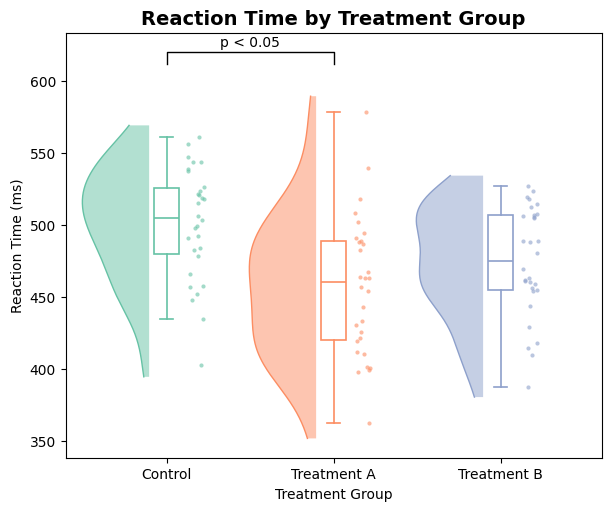

In [6]:
fig, ax = rc.raincloud(data=df, x="group", y="reaction_time", palette=palette, random_state=0)
ax.set_title("Reaction Time by Treatment Group", fontsize=14, fontweight="bold")
ax.set_xlabel("Treatment Group")
ax.set_ylabel("Reaction Time (ms)")
ax.plot([0, 0, 1, 1], [612, 620, 620, 612], color="black", linewidth=1)
ax.annotate("p < 0.05", xy=(0.5, 622), ha="center", va="bottom");
# fig.savefig("raincloud_plot.pdf", dpi=300, bbox_inches="tight")

## 5. Несколько графиков на одной фигуре

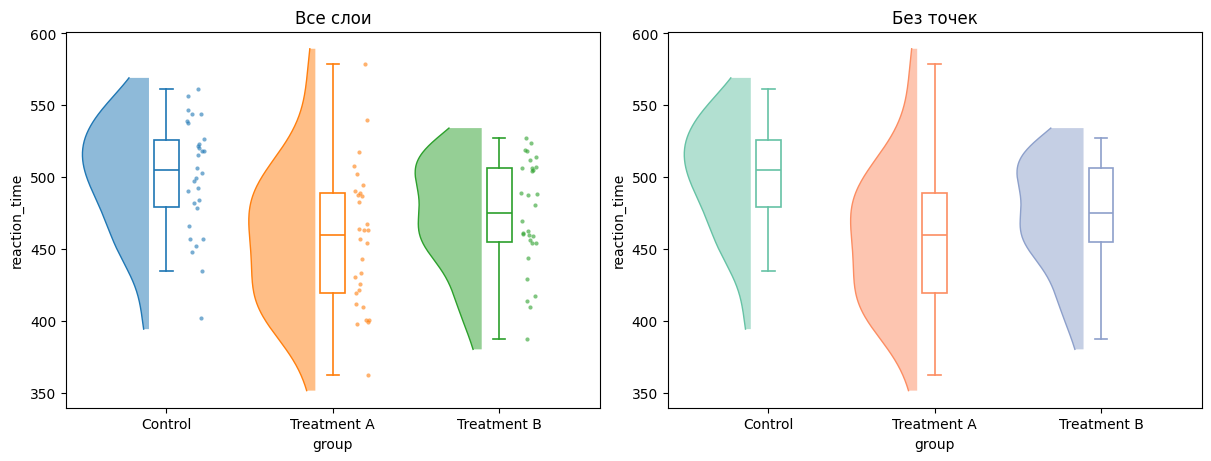

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
rc.raincloud(data=df, x="group", y="reaction_time", ax=ax1, random_state=0)
rc.raincloud(data=df, x="group", y="reaction_time", ax=ax2, palette=palette, add_points=False)
ax1.set_title("Все слои")
ax2.set_title("Без точек");